# Icarus — análise exploratória do Vigitel 2024

**Disciplina:** Análise de Dados · **Grupo:** 1 · **Projeto:** Icarus  
**Integrantes e RAs:**  
Fábiam Damaceno da Silva — 01242039  
Ricardo de Oliveira Nicolau — 01242024  
Izael Reis de Oliveira Junior — 01242032  
Natã Rocha Chaves — 01242140  
Samuel Belarmino da Silva — 01242109  
Paloma Santos Dias — 01242137  
**Data da análise:** 05/10/2026 · **Estado:** estudo exploratório para revisão do grupo.

Este trabalho segue o roteiro do notebook da disciplina e as Aulas 6 e 7. A pergunta central é: **quais referências populacionais sobre atividade física no lazer e sintomas de insônia podem apoiar o contexto do Icarus, sem confundi-las com o desempenho individual no aplicativo?**

A análise usa a edição **2024** da base harmonizada [Vigitel 2006–2024](https://svs.aids.gov.br/daent/cgdnt/vigitel/), publicada pelo Ministério da Saúde. O recorte abrange adultos com **18 anos ou mais das capitais e do Distrito Federal**. O Icarus prioriza 16 a 28 anos, mas o Vigitel não cobre 16 e 17 anos. A ponderação usa `pesorake2025`, conforme as [orientações oficiais](https://svs.aids.gov.br/daent/cgdnt/vigitel/orientacoes-vigitel-2006-2024.pdf). Resultados aqui são **estimativas pontuais descritivas**, sem intervalos de confiança; os testes formais exigem análise que considere o desenho amostral.

## 0. Configuração e proveniência

O ZIP original fica em `dados/fontes/`, fora do versionamento. A célula abaixo exige o SHA-256 observado nesta análise para impedir que uma atualização silenciosa da URL altere os resultados. Para analisar uma nova versão, confira o esquema e registre o novo hash antes de ajustar a configuração.

In [1]:
from pathlib import Path
from hashlib import sha256
import csv
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.titlesize": 12})
pd.set_option("display.max_columns", 50)

NOME_ZIP = "vigitel-2006-2024-peso-rake-csv.zip"
CANDIDATOS = [Path("../dados/fontes") / NOME_ZIP, Path("dados/fontes") / NOME_ZIP]
ARQUIVO = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO is None:
    raise FileNotFoundError("Baixe o ZIP oficial para icarus-data/dados/fontes/; consulte notebooks/README.md.")
HASH_ESPERADO = "40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993"
hash_atual = sha256(ARQUIVO.read_bytes()).hexdigest()
assert hash_atual == HASH_ESPERADO, "A fonte mudou: confira o arquivo antes de atualizar o hash."
with zipfile.ZipFile(ARQUIVO) as pacote:
    nome_csv = pacote.namelist()[0]
    with pacote.open(nome_csv) as arquivo_csv:
        cabecalho = next(csv.reader((linha.decode("latin1") for linha in arquivo_csv)))
print(f"Fonte: {ARQUIVO.name} | SHA-256: {hash_atual}")
print(f"CSV interno: {nome_csv} | colunas de origem: {len(cabecalho)}")

Fonte: vigitel-2006-2024-peso-rake-csv.zip | SHA-256: 40139996d11deb2f52730c90f14e2df4bf5e53aba3cf1848fce391c93ff77993
CSV interno: vigitel-2006-2024-peso-rake_slabel.csv | colunas de origem: 486


## 1. Estrutura, grão e chave

Cada linha representa **uma entrevista concluída**, não uma atividade nem um dia do usuário. `chave` é vazia na edição 2024; o número da linha do arquivo serve apenas para rastrear a leitura local. Não o publicamos nem fazemos junção com dados pessoais do Icarus. A leitura em lotes evita carregar as 486 colunas de todos os anos na memória.

In [2]:
COLUNAS = ["ano", "cidade", "chave", "q6", "q7", "q8_anos", "q47",
           "ativo_livre", "insonia", "r701_hh", "r701_mm", "pesorake2025",
           "q43a", "q43a_ou"]
partes = []
for lote in pd.read_csv(ARQUIVO, compression="zip", encoding="latin1",
                        usecols=COLUNAS, dtype="string", chunksize=50_000):
    recorte = lote.loc[lote["ano"].eq("2024")].copy()
    if not recorte.empty:
        recorte["_linha_origem"] = recorte.index + 2
        partes.append(recorte)
base = pd.concat(partes, ignore_index=True)
assert len(base) == 27_048 and len(cabecalho) == 486
assert base["_linha_origem"].is_unique
print(f"Entrevistas de 2024: {len(base):,}".replace(",", "."))
print(f"Colunas selecionadas: {len(COLUNAS)} de {len(cabecalho)}")
print(f"Chave original preenchida: {base['chave'].notna().sum()}")
print(f"Linhas distintas pelo número da linha no arquivo: {base['_linha_origem'].nunique():,}".replace(",", "."))

Entrevistas de 2024: 27.048
Colunas selecionadas: 14 de 486
Chave original preenchida: 0
Linhas distintas pelo número da linha no arquivo: 27.048


## 2. Qualidade e decisões de tratamento

Na fonte, valores faltantes e códigos devem ser examinados por variável. Converter rótulos para número não pode criar ausências silenciosas. Linhas idênticas **nos campos selecionados** não são entrevistas duplicadas: as colunas não formam uma chave. O texto livre `q43a_ou` é apenas auditado em contagem; nenhuma resposta individual será mostrada.

In [3]:
NUMERICAS = ["q6", "q7", "q8_anos", "q47", "ativo_livre", "insonia",
             "r701_hh", "r701_mm", "pesorake2025"]
dados = base.copy()
perdas = []
for coluna in NUMERICAS:
    antes = dados[coluna].notna().sum()
    dados[coluna] = pd.to_numeric(dados[coluna], errors="coerce")
    perdas.append({"campo": coluna, "perdas_na_conversao": int(antes - dados[coluna].notna().sum())})
assert sum(linha["perdas_na_conversao"] for linha in perdas) == 0
regras = {
    "idade fora de 18 a 120": ~dados["q6"].between(18, 120),
    "sexo fora de 1 ou 2": ~dados["q7"].isin([1, 2]),
    "atividade fora de 0 ou 1": ~dados["ativo_livre"].isin([0, 1]),
    "insônia fora de 0 ou 1": ~dados["insonia"].isin([0, 1]),
    "peso ausente ou não positivo": dados["pesorake2025"].isna() | dados["pesorake2025"].le(0),
}
qualidade = pd.DataFrame({"campo": COLUNAS, "ausentes": [int(base[c].isna().sum()) for c in COLUNAS]})
qualidade["percentual_ausente"] = (qualidade["ausentes"] / len(base) * 100).round(2)
display(qualidade)
display(pd.DataFrame(perdas))
print("Violações de domínio:", {nome: int(mascara.sum()) for nome, mascara in regras.items()})
print("Linhas iguais nos campos selecionados:", int(base[COLUNAS].duplicated().sum()), "(não removidas)")
print("Texto livre preenchido:", int(base["q43a_ou"].notna().sum()))
print("Texto livre fora do código 'outros':",
      int((base["q43a_ou"].notna() & base["q43a"].ne("17").fillna(True)).sum()))
assert all(mascara.sum() == 0 for mascara in regras.values())

,campo,ausentes,percentual_ausente
0,ano,0,0.00
1,cidade,0,0.00
2,chave,27048,100.00
3,q6,0,0.00
4,q7,0,0.00
5,q8_anos,0,0.00
6,q47,0,0.00
7,ativo_livre,0,0.00
8,insonia,0,0.00
9,r701_hh,109,0.40


,campo,perdas_na_conversao
0,q6,0
1,q7,0
2,q8_anos,0
3,q47,0
4,ativo_livre,0
5,insonia,0
6,r701_hh,0
7,r701_mm,0
8,pesorake2025,0


Violações de domínio: {'idade fora de 18 a 120': 0, 'sexo fora de 1 ou 2': 0, 'atividade fora de 0 ou 1': 0, 'insônia fora de 0 ou 1': 0, 'peso ausente ou não positivo': 0}
Linhas iguais nos campos selecionados: 247 (não removidas)
Texto livre preenchido: 1236
Texto livre fora do código 'outros': 13


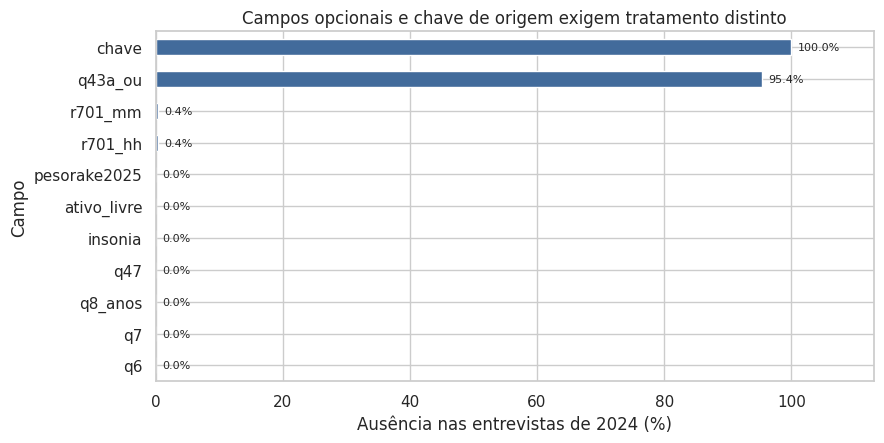

In [4]:
campos_a_plotar = ["chave", "q6", "q7", "q8_anos", "q47", "ativo_livre",
                    "insonia", "r701_hh", "r701_mm", "pesorake2025", "q43a_ou"]
resumo_nulos = qualidade.set_index("campo").loc[campos_a_plotar, "percentual_ausente"]
ax = resumo_nulos.sort_values().plot.barh(color="#426b9b", figsize=(9, 4.6))
ax.set(xlabel="Ausência nas entrevistas de 2024 (%)", ylabel="Campo",
       title="Campos opcionais e chave de origem exigem tratamento distinto")
for i, valor in enumerate(resumo_nulos.sort_values()):
    ax.text(valor + 1, i, f"{valor:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 113)
plt.tight_layout()
plt.show()

**Decisões exploratórias:** `chave` não será usada para unicidade; `q43a_ou` é opcional e requer revisão antes de classificação; as 109 ausências de horas/minutos de sono ficam ausentes, sem imputação; entrevistas não são removidas por igualdade nos campos selecionados. Os 13 textos livres associados a código diferente de “outros” permanecem para revisão da Silver, sem recodificação automática.

## 3. Univariada numérica: idade e duração habitual do sono

A duração habitual é `r701_hh + r701_mm/60`, conforme o dicionário do Vigitel. Ela é uma resposta declarada, não uma medição do app. Valores extremos são **sinalizados para revisão**, sem corte automático. A mediana ponderada usa o peso da pesquisa; percentuais e medianas não usam contagem simples como substituto.

In [5]:
dados["sono_horas"] = dados["r701_hh"] + dados["r701_mm"] / 60

def quantil_ponderado(valores, pesos, probabilidade):
    validos = valores.notna() & pesos.notna() & pesos.gt(0)
    x = valores.loc[validos].to_numpy(dtype=float)
    w = pesos.loc[validos].to_numpy(dtype=float)
    ordem = np.argsort(x)
    return float(x[ordem][np.searchsorted(np.cumsum(w[ordem]), probabilidade * w.sum())])

resumo_numerico = pd.DataFrame([
    {"variavel": "idade (anos)", "n": int(dados["q6"].notna().sum()),
     "minimo": dados["q6"].min(), "mediana_ponderada": quantil_ponderado(dados["q6"], dados["pesorake2025"], .5),
     "p25_ponderado": quantil_ponderado(dados["q6"], dados["pesorake2025"], .25),
     "p75_ponderado": quantil_ponderado(dados["q6"], dados["pesorake2025"], .75), "maximo": dados["q6"].max()},
    {"variavel": "sono habitual (horas)", "n": int(dados["sono_horas"].notna().sum()),
     "minimo": dados["sono_horas"].min(),
     "mediana_ponderada": quantil_ponderado(dados["sono_horas"], dados["pesorake2025"], .5),
     "p25_ponderado": quantil_ponderado(dados["sono_horas"], dados["pesorake2025"], .25),
     "p75_ponderado": quantil_ponderado(dados["sono_horas"], dados["pesorake2025"], .75),
     "maximo": dados["sono_horas"].max()},
])
resumo_numerico["amplitude_interquartil"] = resumo_numerico["p75_ponderado"] - resumo_numerico["p25_ponderado"]
display(resumo_numerico)
print("Sono abaixo de 3 horas:", int(dados["sono_horas"].lt(3).sum()))
print("Sono acima de 12 horas:", int(dados["sono_horas"].gt(12).sum()))
print("Sono não informado:", int(dados["sono_horas"].isna().sum()))

,variavel,n,minimo,mediana_ponderada,p25_ponderado,p75_ponderado,maximo,amplitude_interquartil
0,idade (anos),27048,18.0,43.0,31.0,58.0,99.000000,27.0
1,sono habitual (horas),26939,0.5,7.0,6.0,8.0,15.583333,2.0


Sono abaixo de 3 horas: 256
Sono acima de 12 horas: 31
Sono não informado: 109


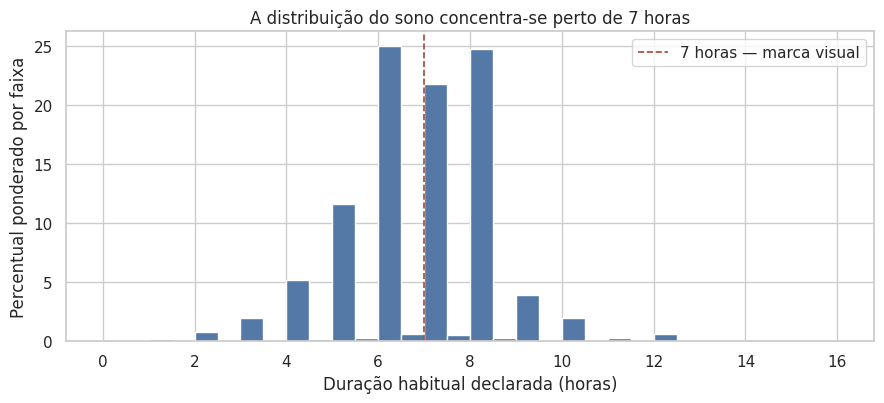

In [6]:
serie_sono = dados.loc[dados["sono_horas"].notna(), ["sono_horas", "pesorake2025"]]
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.hist(serie_sono["sono_horas"], bins=np.arange(0, 16.5, .5),
        weights=serie_sono["pesorake2025"] / serie_sono["pesorake2025"].sum() * 100,
        color="#5579a6", edgecolor="white")
ax.axvline(7, color="#a44738", linestyle="--", linewidth=1.2, label="7 horas — marca visual")
ax.set(xlabel="Duração habitual declarada (horas)", ylabel="Percentual ponderado por faixa",
       title="A distribuição do sono concentra-se perto de 7 horas")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Univariada categórica e população coberta

`q7` codifica sexo registrado pelo inquérito (`1 = masculino`, `2 = feminino`). `q47` indica trabalho declarado (`1 = sim`, `2 = não`). A divisão de 18–24 e 25–28 permite examinar a parte adulta do público prioritário; as demais faixas dão contexto, sem equiparar 29–34 anos ao público do Icarus.

In [7]:
ROTULOS_FAIXA = ["18–24", "25–28", "29–34", "35–49", "50–64", "65+"]
dados["faixa_idade"] = pd.cut(dados["q6"], bins=[17, 24, 28, 34, 49, 64, 120],
                              labels=ROTULOS_FAIXA)
dados["sexo"] = dados["q7"].map({1: "Masculino", 2: "Feminino"})
dados["trabalha"] = dados["q47"].map({1: "Sim", 2: "Não"})
for coluna in ["faixa_idade", "sexo", "trabalha", "ativo_livre", "insonia"]:
    print(f"\n{coluna} — contagem de entrevistas")
    display(dados[coluna].value_counts(dropna=False).rename_axis(coluna).to_frame("n"))
print("Grafias distintas no texto livre opcional:", base["q43a_ou"].nunique(dropna=True))


faixa_idade — contagem de entrevistas


,n
faixa_idade,
35–49,9386
50–64,6776
65+,3429
29–34,3272
18–24,2294
25–28,1891



sexo — contagem de entrevistas


,n
sexo,
Feminino,15160
Masculino,11888



trabalha — contagem de entrevistas


...


ativo_livre — contagem de entrevistas


,n
ativo_livre,
0,15182
1,11866



insonia — contagem de entrevistas


,n
insonia,
0,18267
1,8781


Grafias distintas no texto livre opcional: 568


## 5. Valores extremos

Os extremos da duração habitual não autorizam exclusão por regra genérica de boxplot: podem ser erros ou respostas raras. A análise principal de atividade e insônia não usa essa duração. Antes de publicar uma medida de duração na camada Gold, o grupo deve confrontar os valores com o dicionário e repetir a estimativa com e sem os extremos, documentando a diferença.

In [8]:
extremos = dados["sono_horas"].lt(3) | dados["sono_horas"].gt(12)
print(f"Respostas de sono fora de 3–12 horas, apenas sinalizadas: {int(extremos.sum())}")
print(f"Parcela das respostas válidas: {extremos.sum() / dados['sono_horas'].notna().sum() * 100:.2f}%")
print("Nenhuma entrevista foi excluída por essa sinalização.")

Respostas de sono fora de 3–12 horas, apenas sinalizadas: 287
Parcela das respostas válidas: 1.07%
Nenhuma entrevista foi excluída por essa sinalização.


## 6. Componente temporal

O recorte selecionado contém apenas `ano = 2024`, sem data individual de entrevista entre os campos desta análise. Portanto, **não há série temporal intra-2024 confiável a desenhar**. Uma comparação 2006–2024 exigiria tratar mudanças metodológicas, a ausência de 2022 e as orientações de ponderação da série; isso fica fora desta entrega. Não se atribui tendência a um único ano.

In [9]:
print("Anos disponíveis no recorte:", sorted(dados["ano"].unique().tolist()))

Anos disponíveis no recorte: ['2024']


## 7. Bivariada: atividade, idade e sintomas de insônia

A medida é a **prevalência ponderada** do indicador binário, calculada como soma dos pesos com valor 1 dividida pela soma dos pesos com resposta válida. `ativo_livre` se refere a atividade física suficiente **no lazer, pelo tempo**, conforme o dicionário; `insonia` registra um indicador de sintomas, não diagnóstico clínico. O `n` exibido é a quantidade não ponderada de entrevistas.

In [10]:
def prevalencia_por(grupos, desfecho):
    colunas = list(grupos) + [desfecho, "pesorake2025"]
    subconjunto = dados[colunas].dropna()
    subconjunto = subconjunto[subconjunto["pesorake2025"].gt(0)].copy()
    subconjunto["peso_caso"] = subconjunto[desfecho] * subconjunto["pesorake2025"]
    tabela = (subconjunto.groupby(list(grupos), observed=True, dropna=False)
              .agg(n=(desfecho, "size"), peso_total=("pesorake2025", "sum"),
                   peso_casos=("peso_caso", "sum"))
              .reset_index())
    tabela["prevalencia_pct"] = 100 * tabela["peso_casos"] / tabela["peso_total"]
    return tabela

atividade_faixa = prevalencia_por(["faixa_idade"], "ativo_livre")
insonia_faixa = prevalencia_por(["faixa_idade"], "insonia")
atividade_sexo_faixa = prevalencia_por(["faixa_idade", "sexo"], "ativo_livre")
atividade_por_insonia = prevalencia_por(["insonia"], "ativo_livre")
display(atividade_faixa[["faixa_idade", "n", "prevalencia_pct"]].round(2))
display(insonia_faixa[["faixa_idade", "n", "prevalencia_pct"]].round(2))
display(atividade_por_insonia[["insonia", "n", "prevalencia_pct"]].round(2))

,faixa_idade,n,prevalencia_pct
0,18–24,2294,54.39
1,25–28,1891,54.73
2,29–34,3272,50.79
3,35–49,9386,43.8
4,50–64,6776,35.83
5,65+,3429,27.49


,faixa_idade,n,prevalencia_pct
0,18–24,2294,33.38
1,25–28,1891,29.53
2,29–34,3272,31.84
3,35–49,9386,30.94
4,50–64,6776,33.55
5,65+,3429,30.27


,insonia,n,prevalencia_pct
0,0,18267,45.45
1,1,8781,35.68


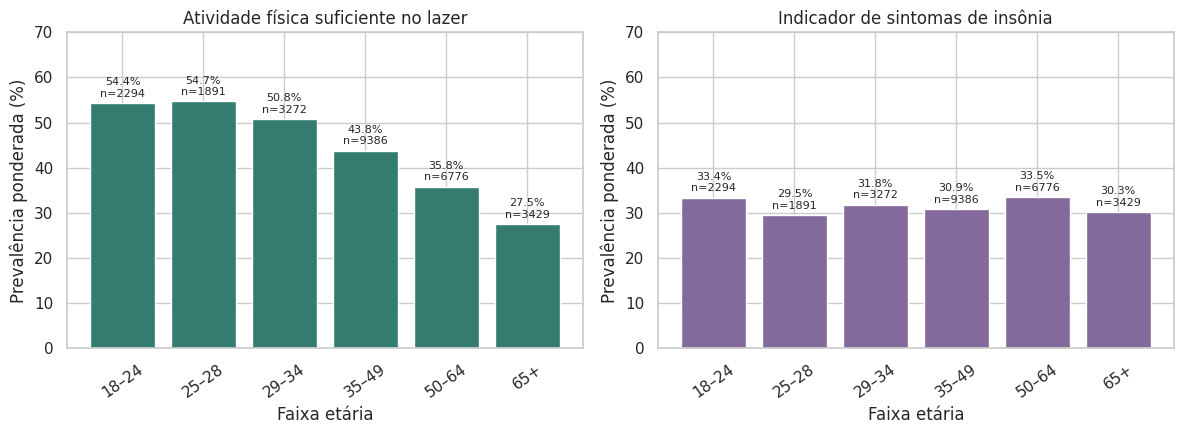

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, tabela, titulo, cor in [
    (axes[0], atividade_faixa, "Atividade física suficiente no lazer", "#347c70"),
    (axes[1], insonia_faixa, "Indicador de sintomas de insônia", "#84699d"),
]:
    barras = ax.bar(tabela["faixa_idade"].astype(str), tabela["prevalencia_pct"], color=cor)
    ax.set(xlabel="Faixa etária", ylabel="Prevalência ponderada (%)", title=titulo, ylim=(0, 70))
    ax.bar_label(barras, labels=[f"{v:.1f}%\nn={n}" for v, n in zip(tabela["prevalencia_pct"], tabela["n"])],
                 padding=3, fontsize=8)
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

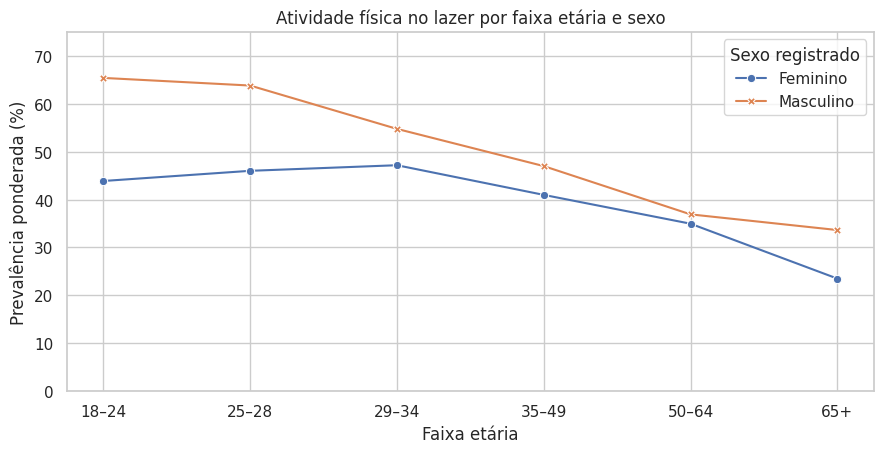

,faixa_idade,sexo,n,prevalencia_pct
0,18–24,Feminino,1208,43.88
1,18–24,Masculino,1086,65.38
2,25–28,Feminino,1017,46.0
3,25–28,Masculino,874,63.79
4,29–34,Feminino,1817,47.17
5,29–34,Masculino,1455,54.75
6,35–49,Feminino,5251,40.98
7,35–49,Masculino,4135,46.99
8,50–64,Feminino,3818,34.96
9,50–64,Masculino,2958,36.91


In [12]:
fig, ax = plt.subplots(figsize=(9, 4.7))
sns.lineplot(data=atividade_sexo_faixa, x="faixa_idade", y="prevalencia_pct",
             hue="sexo", style="sexo", markers=True, dashes=False, ax=ax)
ax.set(xlabel="Faixa etária", ylabel="Prevalência ponderada (%)",
       title="Atividade física no lazer por faixa etária e sexo", ylim=(0, 75))
ax.legend(title="Sexo registrado")
plt.tight_layout()
plt.show()
display(atividade_sexo_faixa[["faixa_idade", "sexo", "n", "prevalencia_pct"]].round(2))

## 8. Correlação e escolha da medida

Uma matriz de Pearson entre códigos como `cidade`, `q7` e `ativo_livre` daria aparência de relação numérica onde há categorias. A análise bivariada usa proporções ponderadas por grupos. Para a duração habitual do sono, uma associação com outros desfechos só deve ser testada após decidir como tratar ausências e extremos. Assim, **não calculamos uma matriz de correlação sem significado substantivo**.

## 9. Segmentação e tamanho de base

Os recortes abaixo ajudam a decidir quais referências populacionais são plausíveis para o app. `n` mede suporte descritivo, não precisão estatística. O limite de supressão para publicação no Icarus ainda será definido no contrato Gold; nenhum limite exploratório deste notebook o substitui.

In [13]:
atividade_sexo = prevalencia_por(["sexo"], "ativo_livre")
atividade_trabalho = prevalencia_por(["trabalha"], "ativo_livre")
atividade_jovens = dados.loc[dados["q6"].between(18, 28), ["ativo_livre", "pesorake2025"]].dropna()
prevalencia_jovens = np.average(atividade_jovens["ativo_livre"].to_numpy(dtype=float),
                                weights=atividade_jovens["pesorake2025"].to_numpy(dtype=float)) * 100
print(f"Público de 18–28 anos nas capitais: n={len(atividade_jovens):,}; atividade={prevalencia_jovens:.2f}%".replace(",", "."))
atividade_total_ponderada = np.average(
    dados["ativo_livre"].to_numpy(dtype=float),
    weights=dados["pesorake2025"].to_numpy(dtype=float)) * 100
insonia_total_ponderada = np.average(
    dados["insonia"].to_numpy(dtype=float),
    weights=dados["pesorake2025"].to_numpy(dtype=float)) * 100
print(f"Total ponderado: atividade={atividade_total_ponderada:.2f}%; sintomas de insônia={insonia_total_ponderada:.2f}%")
print(f"Atividade sem ponderação: {dados['ativo_livre'].mean() * 100:.2f}%")
display(atividade_sexo[["sexo", "n", "prevalencia_pct"]].round(2))
display(atividade_trabalho[["trabalha", "n", "prevalencia_pct"]].round(2))

Público de 18–28 anos nas capitais: n=4.185; atividade=54.52%
Total ponderado: atividade=42.34%; sintomas de insônia=31.75%
Atividade sem ponderação: 43.87%


,sexo,n,prevalencia_pct
0,Feminino,15160,37.88
1,Masculino,11888,47.64


,trabalha,n,prevalencia_pct
0,Não,7963,32.17
1,Sim,19085,47.08


## 10. Multivariada e verificação de confundimento

A diferença observada entre atividade e sintomas de insônia pode variar por idade, sexo, trabalho e escolaridade. A tabela abaixo **estratifica** por faixa e sexo; não ajusta causalmente a associação. A checagem de Simpson é descritiva: uma inversão eventual pediria investigação, e sua ausência não prova independência de confundimento.

In [14]:
estratos = prevalencia_por(["faixa_idade", "sexo", "insonia"], "ativo_livre")
comparacao = estratos.pivot(index=["faixa_idade", "sexo"], columns="insonia",
                            values="prevalencia_pct").reset_index()
comparacao = comparacao.rename(columns={0: "sem_sintomas_pct", 1: "com_sintomas_pct"})
comparacao["diferenca_pp"] = comparacao["com_sintomas_pct"] - comparacao["sem_sintomas_pct"]
display(comparacao.round(2))
print("Estratos com sinal oposto ao agregado:",
      int((comparacao["diferenca_pp"] > 0).sum()), "de", len(comparacao))

insonia,faixa_idade,sexo,sem_sintomas_pct,com_sintomas_pct,diferenca_pp
0,18–24,Feminino,46.52,39.36,-7.16
1,18–24,Masculino,67.05,61.42,-5.63
2,25–28,Feminino,49.76,39.24,-10.52
3,25–28,Masculino,61.82,70.36,8.53
4,29–34,Feminino,52.03,38.18,-13.85
5,29–34,Masculino,55.43,53.03,-2.4
6,35–49,Feminino,45.92,32.33,-13.59
7,35–49,Masculino,49.23,40.19,-9.04
8,50–64,Feminino,37.05,31.68,-5.37
9,50–64,Masculino,41.29,25.06,-16.23


Estratos com sinal oposto ao agregado: 1 de 12


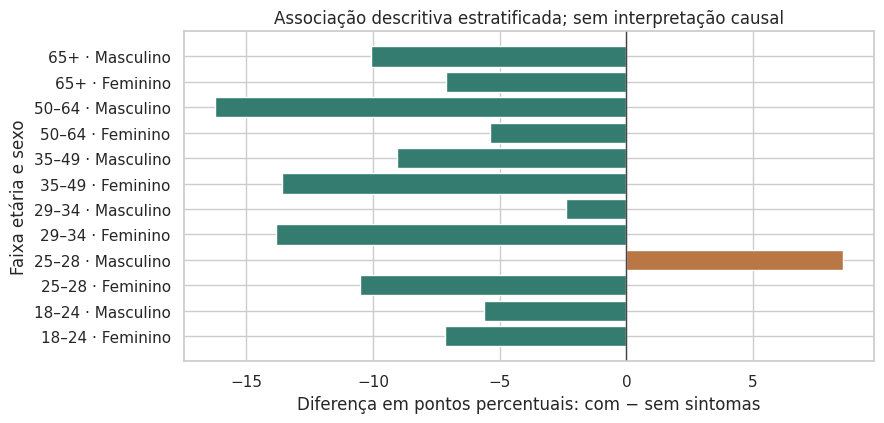

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.4))
cores = ["#347c70" if valor < 0 else "#b87745" for valor in comparacao["diferenca_pp"]]
rotulos = comparacao["faixa_idade"].astype(str) + " · " + comparacao["sexo"]
ax.barh(rotulos, comparacao["diferenca_pp"], color=cores)
ax.axvline(0, color="#444444", linewidth=1)
ax.set(xlabel="Diferença em pontos percentuais: com − sem sintomas",
       ylabel="Faixa etária e sexo", title="Associação descritiva estratificada; sem interpretação causal")
plt.tight_layout()
plt.show()

## 11. Síntese: achados, hipóteses e decisões

### Achados observados nesta versão da fonte

No conjunto das 27.048 entrevistas, a prevalência ponderada é **42,34%** para atividade física suficiente no lazer e **31,75%** para o indicador de sintomas de insônia. A taxa de atividade sem ponderação seria 43,87%, ilustrando por que o peso importa.

1. **Atividade no lazer varia com a idade:** 54,39% no grupo 18–24 e 27,49% no grupo 65+, com `n=2.294` e `n=3.429`, respectivamente (tabela e gráfico da seção 7). Na parte adulta do público prioritário, 18–28 anos, a estimativa conjunta é **54,52%** (`n=4.185`).
2. **A distribuição difere por sexo registrado:** 47,64% no grupo masculino e 37,88% no feminino (seção 9); nas faixas 18–24 e 25–28, as diferenças visuais são maiores que em algumas faixas posteriores (gráfico da seção 7).
3. **Sintomas de insônia se associam a menor atividade declarada no lazer:** 35,68% entre quem tem o indicador e 45,45% entre quem não tem, diferença descritiva de **−9,77 pontos percentuais** (seções 7 e 10). Em **11 dos 12** estratos de idade × sexo a direção é a mesma; entre homens de 25–28 anos, a diferença descritiva se inverte (+8,53 pontos percentuais, `n=215` com sintomas). Essa exceção pede análise de incerteza e confundimento. Não há evidência causal aqui.
4. A duração habitual declarada de sono tem **109 ausências** e alguns extremos a revisar; a mediana ponderada e os percentis estão na seção 3. Sua distribuição não deve ser convertida em duração pessoal de missões.

### Hipóteses a verificar, sem tratá-las como fatos

- A associação entre sintomas de insônia e atividade no lazer pode persistir após ajuste por idade, sexo, estudo, trabalho e capital; a análise formal precisa considerar pesos e desenho amostral.
- Parte da diferença entre faixas e sexos pode refletir composição da amostra e fatores não medidos, e não um efeito isolado dessas variáveis.

### Decisões de tratamento para esta EDA

- Usar `pesorake2025` em todas as prevalências populacionais; mostrar o `n` não ponderado junto.
- Não usar `chave` nem duplicidade dos campos selecionados como razão para remover entrevistas.
- Manter sono ausente como ausente e sinalizar extremos; revisar o dicionário antes de qualquer corte.
- Não classificar automaticamente `q43a_ou`; a opção textual é opcional e há 13 associações divergentes com `q43a`.
- Não publicar microdados, respostas livres nem percentuais de grupos pequenos sem uma política de supressão aprovada.

## 12. Aula 7 — plano de análise estatística

**Objetivo:** descrever e, em análise futura, **explicar associações**, não prever comportamento de um usuário nem decidir intervenções clínicas. O desfecho principal é `ativo_livre` (binário). Preditores candidatos: indicador `insonia`, faixa etária, sexo registrado, anos de estudo e trabalho declarado. `cidade` é um recorte/contexto e possível fonte de variação, não uma escala numérica. As relações são observacionais e transversais.

| Pergunta formal, declarada após a EDA | Método candidato | Confundimento/pressupostos | Tamanho de efeito proposto para discussão |
| --- | --- | --- | --- |
| A prevalência de `ativo_livre` difere entre grupos com/sem indicador de insônia? | Diferença de proporções **ponderadas**, com intervalo de confiança por método de inquérito; depois regressão logística ponderada e prevalências marginais ajustadas. | Ajustar por idade, sexo, estudo, trabalho e capital; confirmar independência, desenho e especificação do modelo. | Diferença ajustada absoluta de **5 pontos percentuais** ou mais, proposta a validar com o grupo antes do teste. |
| A associação varia entre as faixas 18–24 e 25–28 e entre sexos? | Termos de interação no modelo ponderado; comparar diferenças marginais e intervalos. | Evitar multiplicidade oportunista e conferir `n` por estrato. | Mudança de direção ou diferença de **5 pontos percentuais** entre estratos, proposta a validar. |

**Limite inferencial:** os gráficos e percentuais deste notebook são descritivos e não trazem `p`-valor nem significância. O documento oficial pede que pesos **e desenho amostral** sejam considerados. Antes de testar, é preciso escolher ferramenta/método de inquérito apropriado e registrar hipóteses e limiares; estas perguntas foram formuladas **após** olhar a EDA e não são um pré-registro independente. Mesmo uma associação ajustada não prova que dormir mais cause atividade física ou vice-versa.

## 13. Aplicação no Icarus e limites da visão

| Frente do app | Uso sustentado por esta EDA | Limite |
| --- | --- | --- |
| Corpo e saúde | Candidato a referência agregada de atividade física no lazer, com população, edição, peso e `n`. | `ativo_livre` é uma medida da pesquisa; conclusão de missão não mede exercício suficiente. |
| Sono e recuperação | Candidato a referência agregada de sintomas e duração declarada, após revisão metodológica da duração. | Não é diagnóstico, meta de sono ou estimativa a partir do diário pessoal. |
| Dashboard e relatório semanal | Exibir contexto público identificado e separado dos indicadores pessoais, se a Gold for validada. | Não misturar microdados de pesquisas com histórico de usuários. |
| Demais áreas, recompensas e gamificação | Não há medida equivalente nesta base; analisar futuramente com dados reais do app e finalidade explícita. | Ausência de referência pública não significa ausência de valor da área. |
| ATUS 2024 | Fonte separada, já prevista no Icarus, para explorar uso do tempo. | Representa os EUA e não deve ser unido linha a linha ao Vigitel nem usado como norma individual brasileira. |

**Próximo passo técnico:** usar estes candidatos para discutir o contrato Silver/Gold: fórmula, população, recortes, pesos, versão e supressão. Nada neste notebook altera sozinho os requisitos validados do produto ou autoriza publicar um indicador no aplicativo.